<a href="https://colab.research.google.com/github/mahdisahad/WOA-Feature-Selection/blob/main/notebooks/06_Results_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
PROJECT_PATH = Path("/content/drive/MyDrive/WOA_Project")

import sys
sys.path.append(str(PROJECT_PATH))
from dataset_config import *   # <-- dataset-specific code lives only here

RESULTS_PATH = get_results_path(PROJECT_PATH)

df = load_dataset(PROJECT_PATH)

X, y, groups = split_xy(df)

X_train, X_test, y_train, y_test, groups_train = split_train_test(X, y, groups)

duplicate_columns = X_train.columns[
    X_train.T.duplicated()
].tolist()

X_train = X_train.drop(columns=duplicate_columns)
X_test = X_test.drop(columns=duplicate_columns)
X_train, X_test = drop_near_constant(X_train, X_test)

class_labels = sorted(y_train.unique())

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Constant features removed: 35
Training shape: (603, 718)
Testing shape: (153, 718)


In [4]:
selected_features_df = pd.read_csv(
    RESULTS_PATH / "final_woa_selected_features.csv"
)

selected_features = selected_features_df["Feature"].tolist()

print("Number of selected features:", len(selected_features))
print("First 20 selected features:")
print(selected_features[:20])

Number of selected features: 31
First 20 selected features:
['gender', 'GQ_prc5_95', 'GNE_NSR_SEO', 'mean_2nd_delta', 'mean_1st_delta_delta', 'std_MFCC_12th_coef', 'std_10th_delta', 'std_delta_delta_log_energy', 'std_12th_delta_delta', 'Ed_6_coef', 'det_entropy_shannon_3_coef', 'det_entropy_log_9_coef', 'det_TKEO_std_2_coef', 'det_TKEO_std_5_coef', 'app_entropy_shannon_10_coef', 'det_LT_entropy_log_10_coef', 'app_LT_entropy_log_1_coef', 'app_LT_entropy_log_4_coef', 'app_LT_entropy_log_6_coef', 'app_LT_entropy_log_8_coef']


In [5]:
assert len(selected_features) > 0
assert len(set(selected_features)) == len(selected_features)
assert set(selected_features).issubset(set(X_train.columns))

print("Selected features validation passed.")

Selected features validation passed.


In [6]:
X_train_baseline = X_train.copy()
X_test_baseline = X_test.copy()

X_train_woa = X_train[selected_features].copy()
X_test_woa = X_test[selected_features].copy()

print("Baseline training shape:", X_train_baseline.shape)
print("WOA training shape:", X_train_woa.shape)

print("Baseline testing shape:", X_test_baseline.shape)
print("WOA testing shape:", X_test_woa.shape)

Baseline training shape: (603, 718)
WOA training shape: (603, 31)
Baseline testing shape: (153, 718)
WOA testing shape: (153, 31)


In [7]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

woa_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

print("Both models are ready.")

Both models are ready.


In [8]:
baseline_model.fit(X_train_baseline, y_train)

woa_model.fit(X_train_woa, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [9]:
y_pred_baseline = baseline_model.predict(X_test_baseline)

y_pred_woa = woa_model.predict(X_test_woa)

print("Predictions completed.")
print("Baseline predictions:", y_pred_baseline)
print("WOA predictions:", y_pred_woa)

Predictions completed.
Baseline predictions: [1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0
 1 0 0 0 0 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 1 0 0 1 1 1 1 1 1 0 0 1 0 0 0
 1 1 1 1 1 1 0 0 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 1 1
 1 1 0 0 1]
WOA predictions: [1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0
 0 0 0 0 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 0 0 1 0 0 0 0
 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 1 1 1 0 1 0 0 0 1
 1 1 0 0 1]


In [10]:
def evaluate_model(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


baseline_metrics = evaluate_model(
    y_test,
    y_pred_baseline
)

woa_metrics = evaluate_model(
    y_test,
    y_pred_woa
)

comparison_df = pd.DataFrame(
    [baseline_metrics, woa_metrics],
    index=[f"Baseline ({X_train.shape[1]} Features)", f"WOA ({len(selected_features)} Features)"]
)

comparison_df

,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro
Baseline (718 Features),0.764706,0.724022,0.699920,0.724022,0.708879
WOA (31 Features),0.751634,0.723684,0.691176,0.723684,0.700926


In [11]:
print("Baseline Classification Report")

print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=class_labels,
        zero_division=0
    )
)

Baseline Classification Report
              precision    recall  f1-score   support

           0       0.53      0.64      0.58        39
           1       0.87      0.81      0.84       114

    accuracy                           0.76       153
   macro avg       0.70      0.72      0.71       153
weighted avg       0.78      0.76      0.77       153



In [12]:
print("WOA Classification Report")

print(
    classification_report(
        y_test,
        y_pred_woa,
        labels=class_labels,
        zero_division=0
    )
)

WOA Classification Report
              precision    recall  f1-score   support

           0       0.51      0.67      0.58        39
           1       0.87      0.78      0.82       114

    accuracy                           0.75       153
   macro avg       0.69      0.72      0.70       153
weighted avg       0.78      0.75      0.76       153



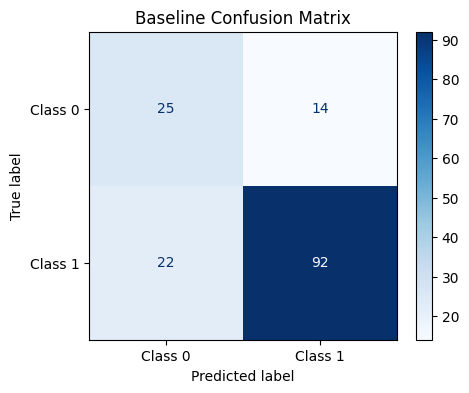

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    labels=class_labels,
    display_labels=[f"Class {c}" for c in class_labels],
    cmap="Blues",
    ax=ax
)

ax.set_title("Baseline Confusion Matrix")
plt.show()

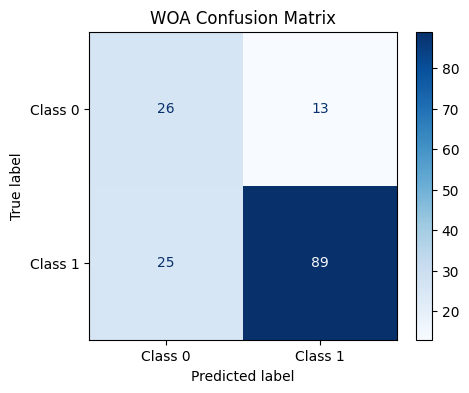

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_woa,
    labels=class_labels,
    display_labels=[f"Class {c}" for c in class_labels],
    cmap="Blues",
    ax=ax
)

ax.set_title("WOA Confusion Matrix")
plt.show()

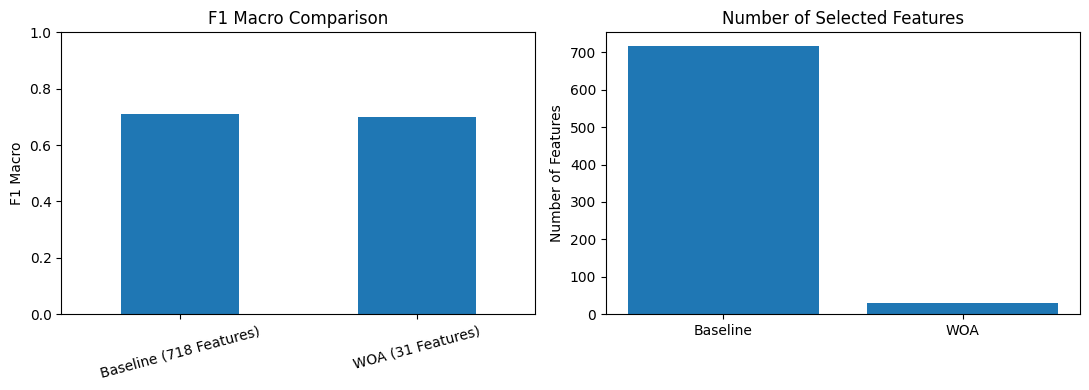

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Compare F1 Macro
comparison_df["F1 Macro"].plot(
    kind="bar",
    ax=axes[0],
    title="F1 Macro Comparison",
    ylim=(0, 1)
)

axes[0].set_ylabel("F1 Macro")
axes[0].tick_params(axis="x", rotation=15)

# Compare feature counts
axes[1].bar(
    ["Baseline", "WOA"],
    [X_train_baseline.shape[1], X_train_woa.shape[1]]
)

axes[1].set_title("Number of Selected Features")
axes[1].set_ylabel("Number of Features")

plt.tight_layout()
plt.show()

In [16]:
original_feature_count = X_train_baseline.shape[1]
selected_feature_count = X_train_woa.shape[1]

reduction_percentage = (
    (original_feature_count - selected_feature_count)
    / original_feature_count
) * 100

print("Original features:", original_feature_count)
print("Selected features:", selected_feature_count)
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original features: 718
Selected features: 31
Feature reduction: 95.68%


In [17]:
comparison_df.to_csv(
    RESULTS_PATH / "final_model_comparison.csv"
)

baseline_report = classification_report(
    y_test,
    y_pred_baseline,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

woa_report = classification_report(
    y_test,
    y_pred_woa,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(baseline_report).to_csv(
    RESULTS_PATH / "baseline_classification_report.csv"
)

pd.DataFrame(woa_report).to_csv(
    RESULTS_PATH / "woa_classification_report.csv"
)

print("Final evaluation results saved successfully.")

Final evaluation results saved successfully.
